# Flight Delay: Logistic Regression และ Random Forest

Notebook ไฟล์เดียว: ตรวจคุณภาพ → คลีน → แบ่งตามเวลา → baseline → จูน → learning curves → ตรวจ overfit → ทดสอบจริง

## วิธีใช้ Run All
เปิดใน Kaggle/Jupyter แล้วเลือก **Run All** ต้องมี Python 3.10+, pandas, numpy, scipy, scikit-learn >=1.2, matplotlib และ IPython
แนะนำ RAM 16 GB; CPU หลาย cores ช่วย Random Forest ได้ โค้ดไม่มีการติดตั้งแพ็กเกจ บันทึกโมเดล export ตาราง หรือ save รูป
ถ้าอยู่ใน Kaggle ให้แนบ [ข้อมูลต้นทาง](https://www.kaggle.com/datasets/patrickzel/flight-delay-and-cancellation-data-2019-2023-v2/data) และเลือกไฟล์ **flights_sample_2m.csv**
หากไม่มีไฟล์แนบ โค้ดจะอ่านไฟล์ public จาก Kaggle เข้า RAM โดยตรง (ต้องเปิด Internet) ไม่มีการเขียน CSV/ZIP ลงดิสก์
หาก API เปลี่ยน/ต้องยืนยันสิทธิ์ ให้แนบข้อมูลผ่าน Add Input หรือกำหนด `DATA_PATH` เป็นไฟล์ต้นทางที่อ่านได้ ไม่ใส่ token ลง notebook

ผลที่ฝึกจริงเก็บเฉพาะ cell outputs ของ notebook เพื่อเปิดดูบน GitHub ได้ ไม่มีไฟล์ผลลัพธ์แยก
เวลารันขึ้นกับเครื่องและงบค้นหา สามารถเพิ่มงบใน configuration ได้ แต่การรันที่ส่งให้ใช้ค่าที่เห็นตรงนี้

## tl;dr — ผลจากรันที่บันทึกไว้

ใช้ข้อมูลต้นทางจริง **2,000,000 แถว × 32 คอลัมน์** หลังคลีนและกำหนด cohort เหลือ **1,942,769 แถว**
ฝึกเต็ม **1,193,757 แถว** ทดสอบช่วง ม.ค.–ส.ค. 2023 จำนวน **304,458 แถว**
ค่าด้านล่างเลือกโมเดลและ threshold ด้วย validation ก่อนเปิด test โดยจูน **F1 ของคลาสล่าช้า**:

- **Logistic Regression** (tuned, threshold=0.495): Accuracy **0.5753**, Precision **0.3015**, Recall **0.6457**, F1 **0.4111**; AP=0.3351.
- **Random Forest** (tuned, threshold=0.475): Accuracy **0.5790**, Precision **0.3045**, Recall **0.6493**, F1 **0.4146**; AP=0.3504.

baseline@0.5 มี Accuracy ราว **77.04%** แต่ Recall/F1 ของเที่ยวบินล่าช้าแทบเป็นศูนย์
ค่าที่เลือกเพิ่มการตรวจจับคลาสล่าช้าโดยแลกกับ false positives และ Accuracy ที่ลดลง ไม่ได้อ้างว่าผลนี้เป็น Accuracy สูงสุด
RF มี F1 สูงกว่าเล็กน้อยใน test นี้ แต่ยังไม่มีช่วงความเชื่อมั่นสำหรับผลต่าง จึงไม่สรุปความเหนือกว่าทั่วไป

**ตรวจ Run All สำเร็จครบ 16 code cells** มีกราฟฝังในไฟล์ **8 ภาพ** รอบที่แนบใช้เวลาราว **18 นาที** บนเครื่องที่แสดงใน Setup
ผลทุกขั้นและพารามิเตอร์อยู่ด้านล่าง ไม่มีโมเดล/CSV/รูปแยกไฟล์
หากเปลี่ยน configuration หรือ environment ให้ดูผลใหม่ใน Results/Takeaways หลัง Run All; สรุปส่วนนี้เป็นบันทึกของรอบที่แนบ

**Repository (private):** [putawann/flight-delay-logistic-rf](https://github.com/putawann/flight-delay-logistic-rf)


## Context & Methods
**เป้าหมาย:** ทำนาย `ARR_DELAY >= 15` นาที (positive = เที่ยวบินล่าช้า) จากข้อมูลตารางบินที่ควรทราบก่อนออกเดินทาง
ใช้เฉพาะเที่ยวบินไม่ยกเลิก ไม่ diverted และมี label ที่ใช้ได้ ประเมินความเสี่ยงแบบมีเงื่อนไขในกลุ่มนี้ ไม่ใช่ทุกเที่ยวบินที่วางแผนไว้

### Key Assumptions
- การ์ดข้อมูลระบุ random sample 2 ล้านแถว 32 คอลัมน์จากปี 2019–สิงหาคม 2023; ตรวจจริงก่อนฝึก
- ไฟล์ย้อนหลังไม่มี schedule snapshot ณ T−120 นาที จึงเป็น retrospective schedule-only experiment ไม่ใช่หลักฐานระบบเตือนก่อนบินจริง
- ไม่ใช้ DEP_DELAY, เวลาเกิดจริง, สาเหตุ delay หรือ cancellation/diversion outcomes เป็น predictors
- ไม่มี TAIL_NUMBER และ weather forecast จึงไม่สมมติว่าทราบการหมุนเวียนลำเครื่องหรืออากาศจริง
- ห้ามใช้ปี 2023 จูน/เลือกโมเดล/threshold ปี 2019–2021 เป็น train; ปี 2022 เป็น validation แบ่งครึ่งปีสำหรับเลือก configuration และ threshold แยกกัน
- จูนแบบ forward-year CV ภายในตัวอย่างฝั่ง train เพื่อคุมเวลา จากนั้นฝึก baseline และ tuned ด้วย train เต็ม
- **จูน F1 ของคลาสล่าช้า** และแสดง Accuracy/Precision/Recall/F1 ครบ เพราะ Accuracy อย่างเดียวอาจได้สูงจากคลาสส่วนใหญ่
- เส้นทาง/สายการบินเดิมข้ามปีได้ตามโจทย์อนาคต ไม่ใช่การทดสอบสนามบินใหม่; ความต่างข้ามปีอาจรวม distribution shift

### 1. Setup และงบการทดลอง

In [1]:
import os, sys, io, gc, json, time, math, hashlib, platform, zipfile, warnings
from pathlib import Path
from urllib.request import Request, urlopen
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterGrid, ParameterSampler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, precision_recall_curve, roc_curve, brier_score_loss)
from sklearn.calibration import calibration_curve
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

SEED = 42
DATA_PATH = None  # Optional read-only path; no raw dataset is written by this notebook.
EXPECTED_ROWS = 2_000_000
DATASET_VERSION = 3
MAX_TUNING_ROWS = 180_000
RF_SEARCH_ITERATIONS = 8
CURVE_SMALL_ROWS = (50_000, 200_000)
MAX_THREADS = min(4, os.cpu_count() or 1)
THRESHOLD_GRID = np.linspace(0.05, 0.8, 151)
DATASET_REF = 'patrickzel/flight-delay-and-cancellation-data-2019-2023-v2'
SOURCE_PAGE = 'https://www.kaggle.com/datasets/' + DATASET_REF + '/data'
DOWNLOAD_URL = ('https://www.kaggle.com/api/v1/datasets/download/' + DATASET_REF
    + '?file_name=flights_sample_2m.csv&datasetVersionNumber=3')

np.random.seed(SEED)
pd.set_option('display.max_columns', 18)
pd.set_option('display.max_rows', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams.update({'figure.figsize': (10, 4.5), 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.alpha': .18, 'figure.dpi': 110})
COLORS = {'Logistic Regression': '#176B87', 'Random Forest': '#A34A28',
          'train': '#176B87', 'validation': '#A34A28'}
run_started = time.perf_counter()
environment = {'Python': platform.python_version(), 'pandas': pd.__version__,
    'numpy': np.__version__, 'scipy': scipy.__version__, 'scikit-learn': sklearn.__version__,
    'matplotlib': matplotlib.__version__, 'CPU logical': os.cpu_count(), 'threads/model': MAX_THREADS}
try:
    import psutil
    environment['RAM total GB'] = round(psutil.virtual_memory().total / 1024**3, 2)
    environment['RAM available GB'] = round(psutil.virtual_memory().available / 1024**3, 2)
except ImportError:
    pass
display(pd.Series(environment, name='Run environment').to_frame())
display(pd.Series({'seed': SEED, 'dataset_version': DATASET_VERSION,
    'tuning_row_budget': MAX_TUNING_ROWS, 'RF_candidates': RF_SEARCH_ITERATIONS,
    'CV_train_years': '2019 -> 2020; 2019–2020 -> 2021',
    'main_train': '2019–2021', 'validation_select': '2022 Jan–Jun',
    'validation_threshold': '2022 Jul–Dec', 'test_locked': '2023 available dates'}, name='Plan').to_frame())

,Run environment
Python,3.12.10
pandas,2.3.3
numpy,2.3.5
scipy,1.16.3
scikit-learn,1.9.1
matplotlib,3.11.2
CPU logical,12
threads/model,4
RAM total GB,15.7800
RAM available GB,10.2300


,Plan
seed,42
dataset_version,3
tuning_row_budget,180000
RF_candidates,8
CV_train_years,2019 -> 2020; 2019–2020 -> 2021
main_train,2019–2021
validation_select,2022 Jan–Jun
validation_threshold,2022 Jul–Dec
test_locked,2023 available dates


## Data
### 2. อ่านข้อมูลต้นทางเข้า RAM และตรวจเวอร์ชัน
อ่าน 32 คอลัมน์เพื่อ audit ก่อนเลือก predictors ค่า missing ของหมวดหมู่ยังไม่ถูกเติมจากข้อมูลรวม
หากพบไฟล์ 10k/100k แทน 2m จะหยุดเพื่อป้องกันผลที่อ้างผิดขนาด

In [2]:
TEXT_COLUMNS = {'FL_DATE', 'AIRLINE', 'AIRLINE_DOT', 'AIRLINE_CODE',
    'ORIGIN', 'ORIGIN_CITY', 'DEST', 'DEST_CITY', 'CANCELLATION_CODE'}
def read_flight_csv(source_factory):
    with source_factory() as handle:
        header = pd.read_csv(handle, nrows=0).columns.tolist()
    dtypes = {c: ('string' if c == 'FL_DATE' else 'category' if c in TEXT_COLUMNS else 'float32')
              for c in header}
    with source_factory() as handle:
        return pd.read_csv(handle, dtype=dtypes, low_memory=False)

input_candidates = []
if DATA_PATH is not None:
    input_candidates = [Path(DATA_PATH)]
elif Path('/kaggle/input').exists():
    for filename in ('flights_sample_2m.csv', 'FLIGHTS_30m_SAMPLE_2m_ALL.csv'):
        input_candidates.extend(Path('/kaggle/input').rglob(filename))
if len(input_candidates) > 1:
    raise ValueError('Multiple 2m inputs found. Set DATA_PATH explicitly to the intended dataset.')
if input_candidates:
    source_description = str(input_candidates[0])
    raw = read_flight_csv(lambda: input_candidates[0].open('rb'))
    source_fingerprint = 'Mounted input; no raw copy created'
else:
    print('Reading public Kaggle file into RAM; no disk extraction...', flush=True)
    request = Request(DOWNLOAD_URL, headers={'User-Agent': 'kaggle-api/1.7.4'})
    archive_buffer = io.BytesIO()
    with urlopen(request, timeout=180) as response:
        content_type = response.headers.get('Content-Type', '')
        expected_bytes = int(response.headers.get('Content-Length', '0'))
        while True:
            block = response.read(2**20)
            if not block:
                break
            archive_buffer.write(block)
    source_fingerprint = hashlib.sha256(archive_buffer.getbuffer()).hexdigest()
    print(f'Received {archive_buffer.tell()/1024**2:.1f} MiB in memory', flush=True)
    archive_buffer.seek(0)
    if zipfile.is_zipfile(archive_buffer):
        archive = zipfile.ZipFile(archive_buffer)
        members = [n for n in archive.namelist() if Path(n).name.lower() in
                   {'flights_sample_2m.csv', 'flights_30m_sample_2m_all.csv'}]
        if len(members) != 1:
            raise ValueError(f'Expected one 2m CSV; archive members: {archive.namelist()}')
        source_description = DATASET_REF + '/version3/' + members[0]
        raw = read_flight_csv(lambda: archive.open(members[0]))
        archive.close()
    else:
        archive_buffer.seek(0)
        raw = read_flight_csv(lambda: io.BytesIO(archive_buffer.getvalue()))
        source_description = DOWNLOAD_URL
    archive_buffer.close()
    del archive_buffer
    gc.collect()

assert len(raw) == EXPECTED_ROWS, f'Wrong row count: {len(raw):,}; expected exactly 2,000,000'
assert raw.shape[1] == 32, f'Schema changed: {raw.shape[1]} columns'
print('SOURCE:', source_description)
print('Compressed source SHA256:', source_fingerprint)
print(f'Observed shape: {raw.shape}; DataFrame RAM: {raw.memory_usage(deep=True).sum()/1024**2:.1f} MiB')
display(raw.head(5))

Reading public Kaggle file into RAM; no disk extraction...


Received 93.2 MiB in memory


SOURCE: patrickzel/flight-delay-and-cancellation-data-2019-2023-v2/version3/flights_sample_2m.csv
Compressed source SHA256: a6efb5a66e1705e211e89a195ade4703acb2366985bf47a9a230b9cce27defab
Observed shape: (2000000, 32); DataFrame RAM: 311.0 MiB


,FL_DATE,AIRLINE,AIRLINE_DOT,AIRLINE_CODE,DOT_CODE,FL_NUMBER,ORIGIN,ORIGIN_CITY,DEST,...,CRS_ELAPSED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,DELAY_DUE_CARRIER,DELAY_DUE_WEATHER,DELAY_DUE_NAS,DELAY_DUE_SECURITY,DELAY_DUE_LATE_AIRCRAFT
0,2020-03-17,United Air Lines Inc.,United Air Lines Inc.: UA,UA,"19,977.0000","1,131.0000",IAH,"Houston, TX",MSY,...,76.0000,63.0000,46.0000,305.0000,NaN,NaN,NaN,NaN,NaN
1,2019-11-03,Southwest Airlines Co.,Southwest Airlines Co.: WN,WN,"19,393.0000","2,650.0000",LAX,"Los Angeles, CA",LAS,...,70.0000,54.0000,44.0000,236.0000,NaN,NaN,NaN,NaN,NaN
2,2020-04-02,Southwest Airlines Co.,Southwest Airlines Co.: WN,WN,"19,393.0000","3,263.0000",OMA,"Omaha, NE",STL,...,75.0000,67.0000,56.0000,342.0000,NaN,NaN,NaN,NaN,NaN
3,2022-09-03,Envoy Air,Envoy Air: MQ,MQ,"20,398.0000","3,936.0000",ORD,"Chicago, IL",CID,...,66.0000,55.0000,36.0000,196.0000,NaN,NaN,NaN,NaN,NaN
4,2021-05-04,Delta Air Lines Inc.,Delta Air Lines Inc.: DL,DL,"19,790.0000","1,614.0000",LAS,"Las Vegas, NV",SLC,...,85.0000,77.0000,56.0000,368.0000,NaN,NaN,NaN,NaN,NaN


### 3. Audit ก่อนคลีน: missing, ชนิดข้อมูล, duplicate และช่วงค่า

,dtype,missing_n,missing_pct,unique_n
CANCELLATION_CODE,category,1947478,97.3739,4
DELAY_DUE_LATE_AIRCRAFT,float32,1643780,82.1890,866
DELAY_DUE_CARRIER,float32,1643780,82.1890,1208
DELAY_DUE_SECURITY,float32,1643780,82.1890,141
DELAY_DUE_NAS,float32,1643780,82.1890,563
DELAY_DUE_WEATHER,float32,1643780,82.1890,696
ARR_DELAY,float32,57231,2.8615,1451
ELAPSED_TIME,float32,57231,2.8615,693
AIR_TIME,float32,57231,2.8615,662
WHEELS_ON,float32,53091,2.6545,1440


,count,mean,std,min,1%,50%,99%,max
DISTANCE,"2,000,000.0000",809.7667,588.6667,29.0000,100.0000,651.0000,"2,588.0000","5,095.0000"
CRS_ELAPSED_TIME,"1,999,983.0000",142.3172,71.6444,-77.0000,48.0000,125.0000,374.0000,705.0000
ARR_DELAY,"1,942,769.0000",4.3020,51.5845,-119.0000,-37.0000,-7.0000,190.0000,"3,237.0000"
CRS_DEP_TIME,"2,000,000.0000","1,327.1642",485.7418,1.0000,520.0000,"1,320.0000","2,252.0000","2,359.0000"
CRS_ARR_TIME,"2,000,000.0000","1,490.4059",511.6216,1.0000,36.0000,"1,516.0000","2,351.0000","2,400.0000"


Exact duplicate rows: 0


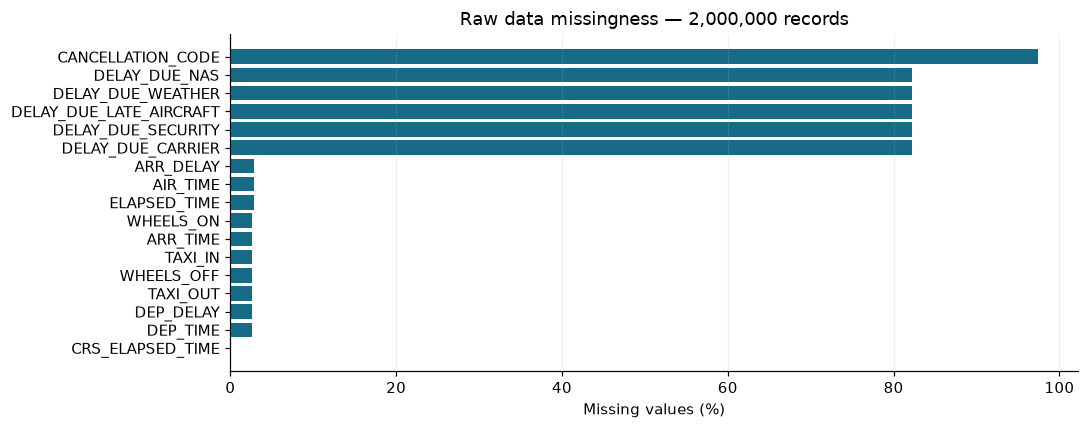

In [3]:
raw_count = len(raw)
required = {'FL_DATE','DOT_CODE','FL_NUMBER','ORIGIN','DEST','CRS_DEP_TIME','CRS_ARR_TIME',
            'CRS_ELAPSED_TIME','DISTANCE','ARR_DELAY','CANCELLED','DIVERTED'}
assert required <= set(raw.columns), f'Missing required columns: {required-set(raw.columns)}'
quality_before = pd.DataFrame({'dtype': raw.dtypes.astype(str),
    'missing_n': raw.isna().sum(), 'missing_pct': raw.isna().mean()*100,
    'unique_n': raw.nunique(dropna=True)}).sort_values('missing_n', ascending=False)
display(quality_before)
display(raw[['DISTANCE','CRS_ELAPSED_TIME','ARR_DELAY','CRS_DEP_TIME','CRS_ARR_TIME']]
        .describe(percentiles=[.01,.5,.99]).T)
exact_duplicates = int(raw.duplicated().sum())
print(f'Exact duplicate rows: {exact_duplicates:,}')
fig, ax = plt.subplots(figsize=(10, 4))
missing = quality_before.loc[quality_before.missing_n > 0, 'missing_pct'].sort_values()
ax.barh(missing.index, missing.values, color='#176B87')
ax.set(title='Raw data missingness — 2,000,000 records', xlabel='Missing values (%)')
ax.grid(axis='y', visible=False)
fig.tight_layout(); plt.show()

### 4. คลีนแบบตรวจสอบจำนวนได้
ลบ exact duplicates, วันที่เสีย/อยู่นอกช่วง, flags ที่ไม่ทราบ outcome และรายการไม่เข้าเงื่อนไข label
แถวที่มี flight key ซ้ำแต่ต่างรายละเอียดจะแยกออกทั้งหมดเพื่อไม่เลือกเวอร์ชันย้อนหลังตามใจ
ค่าระยะทาง/ระยะเวลาตารางที่ใช้ไม่ได้จะเปลี่ยนเป็น missing แล้วให้ imputer เรียนจาก train เท่านั้น
**ไม่ตัด ARR_DELAY สูงด้วย IQR/percentile:** ความล่าช้าสูงอาจเป็นเหตุการณ์จริง

In [4]:
cleaning_steps = []
data = raw.copy()
def retain_rows(mask, reason):
    global data
    before = len(data)
    data = data.loc[mask].copy()
    cleaning_steps.append({'step': reason, 'before_n': before, 'removed_n': before-len(data), 'after_n':len(data)})

retain_rows(~data.duplicated(), 'Remove exact duplicate rows')
data['flight_date'] = pd.to_datetime(data['FL_DATE'], errors='coerce')
retain_rows(data.flight_date.notna(), 'Invalid flight date')
retain_rows(data.flight_date.between('2019-01-01', '2023-12-31'), 'Outside declared 2019–2023 coverage')
retain_rows(data.CANCELLED.isin([0,1]) & data.DIVERTED.isin([0,1]), 'Unknown/invalid cancellation or diversion status')
retain_rows(data.CANCELLED.eq(0), 'Cancelled flights — outside target cohort')
retain_rows(data.DIVERTED.eq(0), 'Diverted flights — outside target cohort')
retain_rows(np.isfinite(data.ARR_DELAY), 'Missing/nonfinite arrival-delay label')
retain_rows(data.ORIGIN.notna() & data.DEST.notna(), 'Missing route endpoints')
flight_key = ['FL_DATE','DOT_CODE','FL_NUMBER','ORIGIN','DEST','CRS_DEP_TIME']
complete_key = data[flight_key].notna().all(axis=1)
ambiguous_key = complete_key & data.duplicated(flight_key, keep=False)
retain_rows(~ambiguous_key, 'Ambiguous repeated event keys; exclude all unresolved versions')

feature_repairs = []
for col in ['DISTANCE','CRS_ELAPSED_TIME']:
    invalid = ~np.isfinite(data[col]) | data[col].le(0)
    feature_repairs.append({'column':col,'invalid_or_missing_n':int(invalid.sum()),'action':'Set NaN; train-only median imputation'})
    data.loc[invalid, col] = np.nan
for col in ['CRS_DEP_TIME','CRS_ARR_TIME']:
    value = pd.to_numeric(data[col], errors='coerce')
    valid = np.isfinite(value) & value.eq(np.floor(value)) & (
        (value.between(0,2359) & (value % 100).lt(60)) | value.eq(2400))
    feature_repairs.append({'column':col,'invalid_or_missing_n':int((~valid).sum()),'action':'Set NaN; 2400 maps to clock midnight only'})
    data.loc[~valid, col] = np.nan
data['delayed'] = data.ARR_DELAY.ge(15).astype('int8')
data = data.sort_values(['flight_date','CRS_DEP_TIME'], kind='mergesort').reset_index(drop=True)
cleaning_audit = pd.DataFrame(cleaning_steps)
assert int(cleaning_audit.removed_n.sum()) + len(data) == raw_count
display(cleaning_audit)
display(pd.DataFrame(feature_repairs))
print(f'Before: {raw_count:,}; after: {len(data):,}; excluded: {raw_count-len(data):,}')
print('Actual eligible coverage:', data.flight_date.min(), 'to', data.flight_date.max())
display(data[['flight_date','ORIGIN','DEST','CRS_DEP_TIME','DISTANCE','ARR_DELAY','delayed']].head())
del raw
gc.collect()

,step,before_n,removed_n,after_n
0,Remove exact duplicate rows,2000000,0,2000000
1,Invalid flight date,2000000,0,2000000
2,Outside declared 2019–2023 coverage,2000000,0,2000000
3,Unknown/invalid cancellation or diversion status,2000000,0,2000000
4,Cancelled flights — outside target cohort,2000000,52522,1947478
5,Diverted flights — outside target cohort,1947478,4709,1942769
6,Missing/nonfinite arrival-delay label,1942769,0,1942769
7,Missing route endpoints,1942769,0,1942769
8,Ambiguous repeated event keys; exclude all unr...,1942769,0,1942769


,column,invalid_or_missing_n,action
0,DISTANCE,0,Set NaN; train-only median imputation
1,CRS_ELAPSED_TIME,1,Set NaN; train-only median imputation
2,CRS_DEP_TIME,0,Set NaN; 2400 maps to clock midnight only
3,CRS_ARR_TIME,0,Set NaN; 2400 maps to clock midnight only


Before: 2,000,000; after: 1,942,769; excluded: 57,231
Actual eligible coverage: 2019-01-01 00:00:00 to 2023-08-31 00:00:00


,flight_date,ORIGIN,DEST,CRS_DEP_TIME,DISTANCE,ARR_DELAY,delayed
0,2019-01-01,PHX,ANC,15.0000,"2,552.0000",-10.0000,0
1,2019-01-01,SFO,IAH,50.0000,"1,635.0000",-1.0000,0
2,2019-01-01,LAS,CLT,107.0000,"1,916.0000",0.0000,0
3,2019-01-01,PSE,MCO,435.0000,"1,179.0000",-22.0000,0
4,2019-01-01,BOS,MYR,505.0000,738.0000,-16.0000,0


0

### 5. ฟีเจอร์ deterministic และชุดข้อมูลตามเวลา
จำนวนคอลัมน์ดิบไม่เท่ากับจำนวน predictors ที่ใช้ได้ก่อนบิน สร้าง calendar/route/clock features จากข้อมูลตามตารางเท่านั้น
`2400` เปลี่ยนเป็นมุมเวลาเที่ยงคืนเพื่อสร้าง sin/cos ไม่ใช้อนุมาน UTC หรือวันมาถึง
ไม่ดูคะแนน test ในขั้นพัฒนา ตารางขนาดแสดงเฉพาะจำนวนและช่วงวันที่; prevalence ของ test แสดงตอนประเมินสุดท้าย

In [5]:
feature_data = pd.DataFrame(index=data.index)
for source, name in [('DOT_CODE','airline'),('FL_NUMBER','flight_number')]:
    valid_integer = data[source].notna() & data[source].eq(np.floor(data[source]))
    values = data[source].where(valid_integer).astype('Int64').astype('string')
    feature_data[name] = values.astype(object).where(values.notna(), np.nan)
for source, name in [('ORIGIN','origin'),('DEST','destination')]:
    feature_data[name] = data[source].astype(object)
feature_data['route'] = feature_data.origin + '>' + feature_data.destination
feature_data['month'] = data.flight_date.dt.month.astype(str)
feature_data['weekday'] = data.flight_date.dt.dayofweek.astype(str)
for source, name in [('CRS_DEP_TIME','departure'),('CRS_ARR_TIME','arrival')]:
    v = data[source]
    minutes = ((v//100)*60 + v%100) % (24*60)
    feature_data[name+'_sin'] = np.sin(2*np.pi*minutes/1440).astype('float32')
    feature_data[name+'_cos'] = np.cos(2*np.pi*minutes/1440).astype('float32')
feature_data['distance'] = data.DISTANCE.astype('float32')
feature_data['scheduled_duration'] = data.CRS_ELAPSED_TIME.astype('float32')
CAT = ['airline','flight_number','origin','destination','route','month','weekday']
NUM = ['departure_sin','departure_cos','arrival_sin','arrival_cos','distance','scheduled_duration']
FEATURES = CAT + NUM
BANNED = {'ARR_DELAY','DEP_DELAY','DEP_TIME','ARR_TIME','AIR_TIME','ELAPSED_TIME',
    'CANCELLED','DIVERTED','CANCELLATION_CODE','TAXI_OUT','TAXI_IN','WHEELS_OFF','WHEELS_ON'}
assert not (set(FEATURES) & BANNED)
X = feature_data[FEATURES]
y = data.delayed
dates = data.flight_date
train_ids = data.index[dates.lt('2022-01-01')]
val_select_ids = data.index[dates.between('2022-01-01','2022-06-30')]
val_threshold_ids = data.index[dates.between('2022-07-01','2022-12-31')]
test_ids = data.index[dates.ge('2023-01-01')]
splits = {'Train':train_ids,'Validation: select':val_select_ids,
          'Validation: threshold':val_threshold_ids,'Test: locked':test_ids}
assert sum(map(len,splits.values())) == len(data)
assert len(set(train_ids)&set(test_ids)) == 0
assert dates.loc[train_ids].max() < dates.loc[val_select_ids].min()
assert dates.loc[val_select_ids].max() < dates.loc[val_threshold_ids].min()
assert dates.loc[val_threshold_ids].max() < dates.loc[test_ids].min()
split_table = pd.DataFrame([{'split':name,'rows':len(ids),
    'share_pct':len(ids)/len(data)*100,'from':dates.loc[ids].min().date(),
    'to':dates.loc[ids].max().date()} for name,ids in splits.items()])
display(split_table)
for name, ids in list(splits.items())[:3]:
    assert y.loc[ids].nunique() == 2, f'{name} has only one class'
display(pd.DataFrame([{'split':name,'delayed_n':int(y.loc[ids].sum()),
    'delayed_rate':float(y.loc[ids].mean())} for name,ids in list(splits.items())[:3]]))
print('Predictors:', FEATURES)
print('Full schema fields:', 32, '| engineered predictors:', len(FEATURES))

,split,rows,share_pct,from,to
0,Train,1193757,61.4462,2019-01-01,2021-12-31
1,Validation: select,217402,11.1903,2022-01-01,2022-06-30
2,Validation: threshold,227152,11.6922,2022-07-01,2022-12-31
3,Test: locked,304458,15.6713,2023-01-01,2023-08-31


,split,delayed_n,delayed_rate
0,Train,192860,0.1616
1,Validation: select,46122,0.2122
2,Validation: threshold,47339,0.2084


Predictors: ['airline', 'flight_number', 'origin', 'destination', 'route', 'month', 'weekday', 'departure_sin', 'departure_cos', 'arrival_sin', 'arrival_cos', 'distance', 'scheduled_duration']
Full schema fields: 32 | engineered predictors: 13


### 6. EDA เฉพาะ train: ขนาดรายปีและอัตราล่าช้ารายเดือน

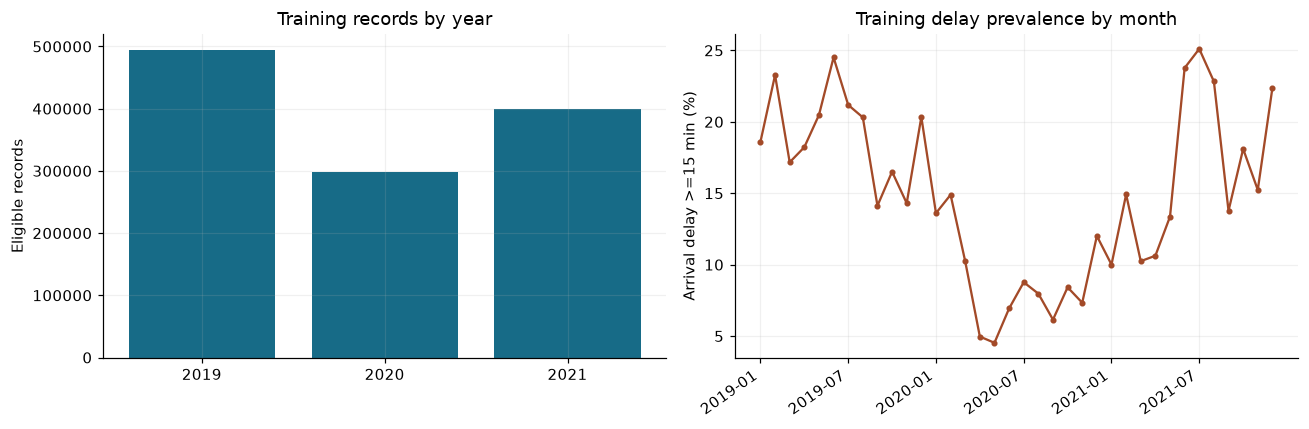

47

In [6]:
train_eda = data.loc[train_ids, ['flight_date','delayed']].copy()
train_eda['period'] = train_eda.flight_date.dt.to_period('M').astype(str)
monthly_train = train_eda.groupby('period', observed=True).agg(rows=('delayed','size'), delayed_rate=('delayed','mean'))
fig, axes = plt.subplots(1,2,figsize=(12,4))
year_counts = train_eda.flight_date.dt.year.value_counts().sort_index()
axes[0].bar(year_counts.index.astype(str),year_counts.values,color='#176B87')
axes[0].set(title='Training records by year',ylabel='Eligible records')
axes[1].plot(monthly_train.index,monthly_train.delayed_rate*100,color='#A34A28',marker='o',markersize=3)
ticks=np.arange(0,len(monthly_train),6)
axes[1].set_xticks(ticks,monthly_train.index[ticks],rotation=35,ha='right')
axes[1].set(title='Training delay prevalence by month',ylabel='Arrival delay >=15 min (%)')
fig.tight_layout(); plt.show()
del train_eda
gc.collect()

## Results
### 7. Pipeline, metrics และเครื่องมือวัด
one-hot จัดกลุ่ม rare categories จาก **train ในแต่ละ fit เท่านั้น** เพื่อคุม RAM: baseline จำกัด 128 categories ต่อฟีเจอร์
ไม่สร้าง target encoding จากข้อมูลรวม Numeric scaler ใช้กับ Logistic เท่านั้น Random Forest ไม่ต้อง scale
เก็บโมเดลและผล intermediate ใน RAM ไม่มี `joblib.dump`, `to_csv` หรือ `savefig`

In [7]:
def make_pipeline(name, overrides=None):
    cat_pipe=Pipeline([('imputer',SimpleImputer(strategy='constant',fill_value='__MISSING__')),
        ('onehot',OneHotEncoder(handle_unknown='infrequent_if_exist',min_frequency=30,
                               max_categories=128,sparse_output=True,dtype=np.float32))])
    numeric_steps=[('imputer',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True))]
    if name=='Logistic Regression': numeric_steps.append(('scale',StandardScaler()))
    preprocessor=ColumnTransformer([('cat',cat_pipe,CAT),('num',Pipeline(numeric_steps),NUM)],
                                  sparse_threshold=1.0)
    if name=='Logistic Regression':
        estimator=LogisticRegression(solver='liblinear',C=1.0,max_iter=1500,
                                    tol=1e-4,random_state=SEED)
    else:
        estimator=RandomForestClassifier(n_estimators=64,max_depth=24,min_samples_leaf=1,
            max_features='sqrt',n_jobs=MAX_THREADS,random_state=SEED)
    result=Pipeline([('preprocess',preprocessor),('model',estimator)])
    if overrides: result.set_params(**overrides)
    return result

def metrics_from_probability(actual, probability, threshold=.5):
    prediction=np.asarray(probability)>=threshold
    return {'Accuracy':accuracy_score(actual,prediction),
        'Precision':precision_score(actual,prediction,zero_division=0),
        'Recall':recall_score(actual,prediction,zero_division=0),
        'F1':f1_score(actual,prediction,zero_division=0),
        'AP':average_precision_score(actual,probability),
        'ROC_AUC':roc_auc_score(actual,probability),
        'Brier':brier_score_loss(actual,probability)}

fit_records=[]
def fit_pipeline(estimator, ids, label):
    start=time.perf_counter()
    with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=MAX_THREADS):
        warnings.simplefilter('always',ConvergenceWarning)
        estimator.fit(X.loc[ids],y.loc[ids])
    elapsed=time.perf_counter()-start
    convergence=[str(w.message) for w in caught if issubclass(w.category,ConvergenceWarning)]
    if convergence:
        raise RuntimeError(f'Convergence failed for {label}: {convergence[0]}. Increase max_iter/check scaling before reporting.')
    fit_records.append({'fit':label,'training_rows':len(ids),'fit_seconds':elapsed})
    print(f'{label}: {len(ids):,} train rows; fit {elapsed:.1f}s',flush=True)
    return estimator

def evaluate(estimator, ids, threshold=.5):
    with threadpool_limits(limits=MAX_THREADS):
        probability=estimator.predict_proba(X.loc[ids])[:,1]
    return metrics_from_probability(y.loc[ids],probability,threshold), probability

NAMES=['Logistic Regression','Random Forest']
cv_ids=pd.Index(np.sort(np.random.default_rng(SEED).choice(train_ids,
    size=min(MAX_TUNING_ROWS,len(train_ids)),replace=False)))
cv_year=dates.loc[cv_ids].dt.year
cv_folds=[(cv_ids[cv_year.le(2019)],cv_ids[cv_year.eq(2020)]),
          (cv_ids[cv_year.le(2020)],cv_ids[cv_year.eq(2021)])]
display(pd.DataFrame([{'fold':i+1,'train_n':len(a),'validation_n':len(b),
    'train_end':dates.loc[a].max().date(),'validation_start':dates.loc[b].min().date(),
    'validation_end':dates.loc[b].max().date()} for i,(a,b) in enumerate(cv_folds)]))
assert all(dates.loc[a].max()<dates.loc[b].min() for a,b in cv_folds)

,fold,train_n,validation_n,train_end,validation_start,validation_end
0,1,74467,45199,2019-12-31,2020-01-01,2020-12-31
1,2,119666,60334,2020-12-31,2021-01-01,2021-12-31


### 8. จูนจาก forward-year CV ภายใน train
ค้น 8 configurations ต่อโมเดล (2 chronological folds ต่อ configuration) เทียบ F1@0.5 เป็นหลักและบันทึก Accuracy/AP ด้วย
Logistic: C และ class weight; RF: depth, leaf size, feature sampling, row sampling, tree count และ rare-category cap
CV เป็นการคัดกรองด้วยตัวอย่างที่สุ่มเฉพาะฝั่ง train แล้วคงลำดับปี ไม่ใช่การลดขนาดชุดฝึกสุดท้าย

In [8]:
lr_candidates=list(ParameterGrid({'model__C':[.03,.15,1.,5.],
                                 'model__class_weight':[None,'balanced']}))
rf_space={'model__n_estimators':[64,96], 'model__max_depth':[8,14,20],
    'model__min_samples_leaf':[10,50,200], 'model__max_features':['sqrt',.12,.25],
    'model__max_samples':[.6,.85], 'model__class_weight':[None,'balanced_subsample'],
    'preprocess__cat__onehot__max_categories':[64,128]}
rf_candidates=list(ParameterSampler(rf_space,n_iter=RF_SEARCH_ITERATIONS,random_state=SEED))
candidates={'Logistic Regression':lr_candidates,'Random Forest':rf_candidates}
search_rows=[]
best_parameters={}
for name in NAMES:
    print('\nSearching',name,flush=True)
    local_rows=[]
    for candidate_id,params in enumerate(candidates[name],1):
        fold_metrics=[]
        for fold_id,(fit_ids,hold_ids) in enumerate(cv_folds,1):
            model=fit_pipeline(make_pipeline(name,params),fit_ids,f'{name} search {candidate_id}/{len(candidates[name])} fold {fold_id}')
            scores,_=evaluate(model,hold_ids)
            fold_metrics.append(scores)
            del model
            gc.collect()
        row={'model':name,'candidate':candidate_id,'CV_F1_mean':np.mean([s['F1'] for s in fold_metrics]),
             'CV_F1_std':np.std([s['F1'] for s in fold_metrics]),
             'CV_Accuracy_mean':np.mean([s['Accuracy'] for s in fold_metrics]),
             'CV_AP_mean':np.mean([s['AP'] for s in fold_metrics]),'parameters':params}
        local_rows.append(row); search_rows.append(row)
        print(f"  candidate {candidate_id}: CV F1={row['CV_F1_mean']:.4f}, Accuracy={row['CV_Accuracy_mean']:.4f}",flush=True)
    winner=max(local_rows,key=lambda r:(r['CV_F1_mean'],r['CV_AP_mean']))
    best_parameters[name]=winner['parameters']
    print('CV-selected parameters:',best_parameters[name],flush=True)
search_results=pd.DataFrame(search_rows)
display(search_results.sort_values(['model','CV_F1_mean'],ascending=[True,False]).reset_index(drop=True))
print('F1 is the tuning objective. Highest Accuracy candidate may be different; no global optimum is claimed.')


Searching Logistic Regression


Logistic Regression search 1/8 fold 1: 74,467 train rows; fit 0.6s


Logistic Regression search 1/8 fold 2: 119,666 train rows; fit 0.9s


  candidate 1: CV F1=0.0013, Accuracy=0.8642


Logistic Regression search 2/8 fold 1: 74,467 train rows; fit 0.6s


...

Random Forest search 8/8 fold 2: 119,666 train rows; fit 2.4s


  candidate 8: CV F1=0.0000, Accuracy=0.8644


CV-selected parameters: {'preprocess__cat__onehot__max_categories': 64, 'model__n_estimators': 64, 'model__min_samples_leaf': 50, 'model__max_samples': 0.85, 'model__max_features': 0.25, 'model__max_depth': 20, 'model__class_weight': 'balanced_subsample'}


,model,candidate,CV_F1_mean,CV_F1_std,CV_Accuracy_mean,CV_AP_mean,parameters
0,Logistic Regression,2,0.2628,0.0633,0.5908,0.1868,"{'model__C': 0.03, 'model__class_weight': 'bal..."
1,Logistic Regression,4,0.2615,0.0634,0.5899,0.1859,"{'model__C': 0.15, 'model__class_weight': 'bal..."
2,Logistic Regression,6,0.2606,0.0622,0.5884,0.1850,"{'model__C': 1.0, 'model__class_weight': 'bala..."
3,Logistic Regression,8,0.2603,0.0624,0.5878,0.1847,"{'model__C': 5.0, 'model__class_weight': 'bala..."
4,Logistic Regression,7,0.0074,0.0051,0.8638,0.1858,"{'model__C': 5.0, 'model__class_weight': None}"
5,Logistic Regression,5,0.0063,0.0044,0.8639,0.1861,"{'model__C': 1.0, 'model__class_weight': None}"
6,Logistic Regression,3,0.0032,0.0022,0.8640,0.1872,"{'model__C': 0.15, 'model__class_weight': None}"
7,Logistic Regression,1,0.0013,0.0009,0.8642,0.1881,"{'model__C': 0.03, 'model__class_weight': None}"
8,Random Forest,1,0.2649,0.0668,0.6240,0.1932,{'preprocess__cat__onehot__max_categories': 64...
9,Random Forest,7,0.2644,0.0664,0.6239,0.1940,{'preprocess__cat__onehot__max_categories': 64...


F1 is the tuning objective. Highest Accuracy candidate may be different; no global optimum is claimed.


### 9. ฝึก baseline และ tuned ด้วย train เต็ม แล้วตรวจ validation ครึ่งแรก
ทุก configuration ฝึกด้วยแถวที่เข้าเงื่อนไขทั้งหมดของ 2019–2021 เลือก baseline/tuned ด้วย F1 ของ validation Jan–Jun 2022
คะแนน train ใช้ดูช่องว่าง ไม่ใช่ผลประเมินทั่วไป และช่องว่างอาจมีทั้ง overfit กับความต่างข้ามปี

In [9]:
models={}
development_rows=[]
development_probabilities={}
for name in NAMES:
    for variant,params in [('baseline',{}),('tuned',best_parameters[name])]:
        model=fit_pipeline(make_pipeline(name,params),train_ids,f'{name} {variant} FULL TRAIN')
        models[(name,variant)]=model
        for split,ids in [('train',train_ids),('validation_select',val_select_ids)]:
            score,prob=evaluate(model,ids)
            development_rows.append({'model':name,'variant':variant,'split':split,'threshold':.5,**score})
            if split=='validation_select': development_probabilities[(name,variant)]=prob
        feature_count=model.named_steps['preprocess'].get_feature_names_out().size
        print(f'{name} {variant}: encoded features={feature_count}',flush=True)
development_results=pd.DataFrame(development_rows)
display(development_results)
chosen_variants={}
for name in NAMES:
    scores=development_results.query("model==@name and split=='validation_select'")
    winner=scores.sort_values(['F1','AP'],ascending=False,kind='stable').iloc[0]
    chosen_variants[name]=winner['variant']
display(pd.DataFrame([{'model':name,'chosen_variant':chosen_variants[name],
    'selection_data':'2022 Jan–Jun only'} for name in NAMES]))

Logistic Regression baseline FULL TRAIN: 1,193,757 train rows; fit 14.1s


Logistic Regression baseline: encoded features=556


Logistic Regression tuned FULL TRAIN: 1,193,757 train rows; fit 15.2s


Logistic Regression tuned: encoded features=556


Random Forest baseline FULL TRAIN: 1,193,757 train rows; fit 342.2s


Random Forest baseline: encoded features=556


Random Forest tuned FULL TRAIN: 1,193,757 train rows; fit 450.4s


Random Forest tuned: encoded features=300


,model,variant,split,threshold,Accuracy,Precision,Recall,F1,AP,ROC_AUC,Brier
0,Logistic Regression,baseline,train,0.5000,0.8384,0.4795,0.0002,0.0004,0.2549,0.6415,0.1305
1,Logistic Regression,baseline,validation_select,0.5000,0.7879,0.6667,0.0003,0.0005,0.3077,0.6292,0.1639
2,Logistic Regression,tuned,train,0.5000,0.5956,0.2246,0.6130,0.3288,0.2526,0.6417,0.2349
3,Logistic Regression,tuned,validation_select,0.5000,0.6014,0.2852,0.5834,0.3831,0.3046,0.6281,0.2340
4,Random Forest,baseline,train,0.5000,0.8386,1.0000,0.0013,0.0025,0.4736,0.7865,0.1211
5,Random Forest,baseline,validation_select,0.5000,0.7879,0.8000,0.0001,0.0002,0.3189,0.6368,0.1637
6,Random Forest,tuned,train,0.5000,0.6528,0.2599,0.6217,0.3665,0.3072,0.6967,0.2188
7,Random Forest,tuned,validation_select,0.5000,0.6340,0.2949,0.5212,0.3767,0.3153,0.6349,0.2252


,model,chosen_variant,selection_data
0,Logistic Regression,tuned,2022 Jan–Jun only
1,Random Forest,tuned,2022 Jan–Jun only


### 10. Learning curves: ก่อน–หลัง regularization
ใช้ nested random subsets จาก train (ทุก subset ยังอยู่ก่อนปี 2022) เพื่อให้การเปลี่ยนขนาดไม่เท่ากับการเปลี่ยนปีไปพร้อมกัน
จุดสุดท้ายใช้โมเดล full train ที่ฝึกแล้ว ไม่มีการฝึกซ้ำโดยไม่จำเป็น แต่ละจุดเป็น seed เดียว ไม่มี confidence band
ใช้ validation Jan–Jun เดิมและ threshold 0.5 เพื่อเปรียบเทียบช่องว่างโดยไม่ปนผลการปรับ threshold

Logistic Regression baseline learning curve n=50000: 50,000 train rows; fit 0.5s


Logistic Regression baseline learning curve n=200000: 200,000 train rows; fit 2.3s


Logistic Regression tuned learning curve n=50000: 50,000 train rows; fit 0.4s


Logistic Regression tuned learning curve n=200000: 200,000 train rows; fit 2.0s


Random Forest baseline learning curve n=50000: 50,000 train rows; fit 2.7s


Random Forest baseline learning curve n=200000: 200,000 train rows; fit 17.4s


Random Forest tuned learning curve n=50000: 50,000 train rows; fit 4.0s


Random Forest tuned learning curve n=200000: 200,000 train rows; fit 29.5s


,model,variant,train_rows,split,F1,Accuracy
0,Logistic Regression,baseline,50000,train,0.0017,0.8380
1,Logistic Regression,baseline,50000,validation_select,0.0016,0.7878
2,Logistic Regression,baseline,200000,train,0.0006,0.8390
3,Logistic Regression,baseline,200000,validation_select,0.0007,0.7879
4,Logistic Regression,baseline,1193757,train,0.0004,0.8384
5,Logistic Regression,baseline,1193757,validation_select,0.0005,0.7879
6,Logistic Regression,tuned,50000,train,0.3303,0.5995
7,Logistic Regression,tuned,50000,validation_select,0.3792,0.5975
8,Logistic Regression,tuned,200000,train,0.3283,0.5963
9,Logistic Regression,tuned,200000,validation_select,0.3808,0.6018


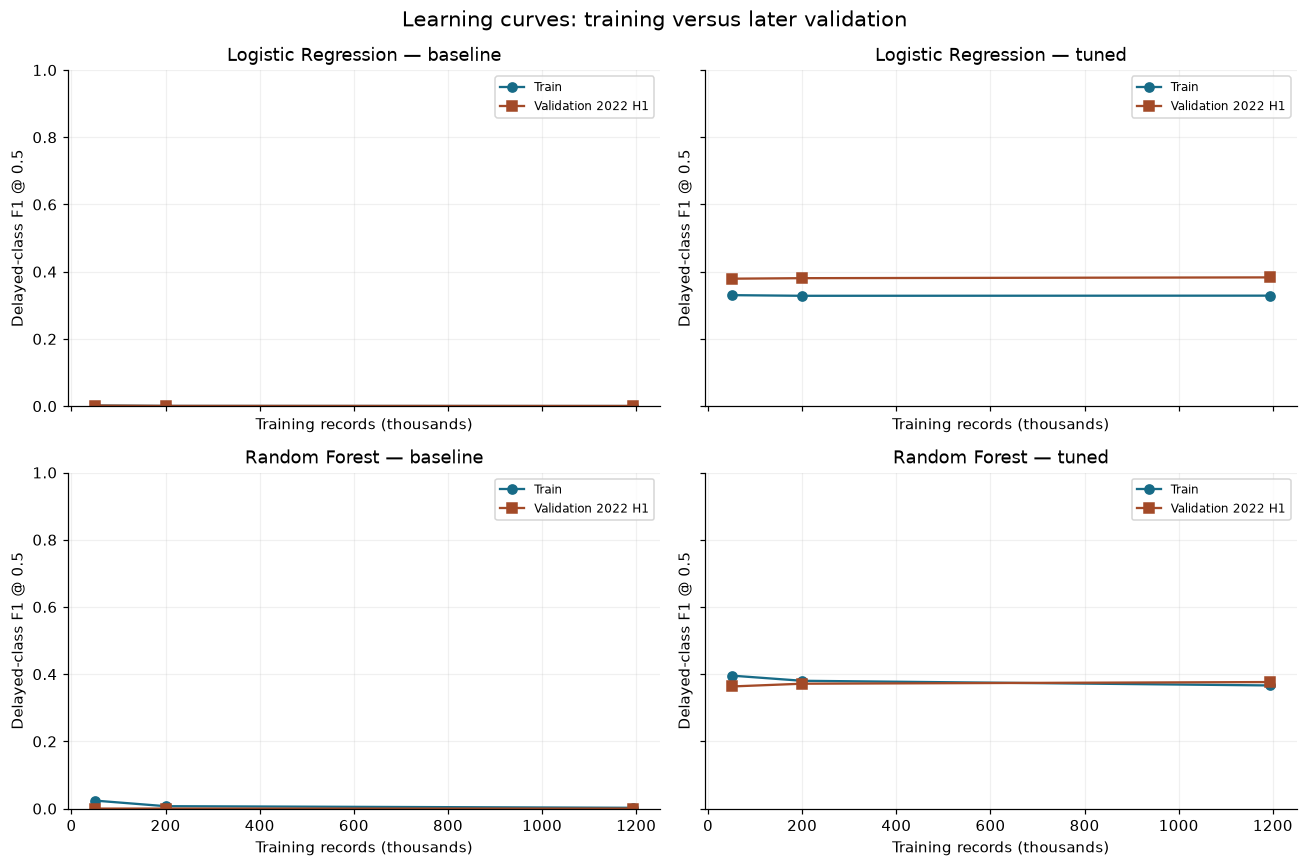

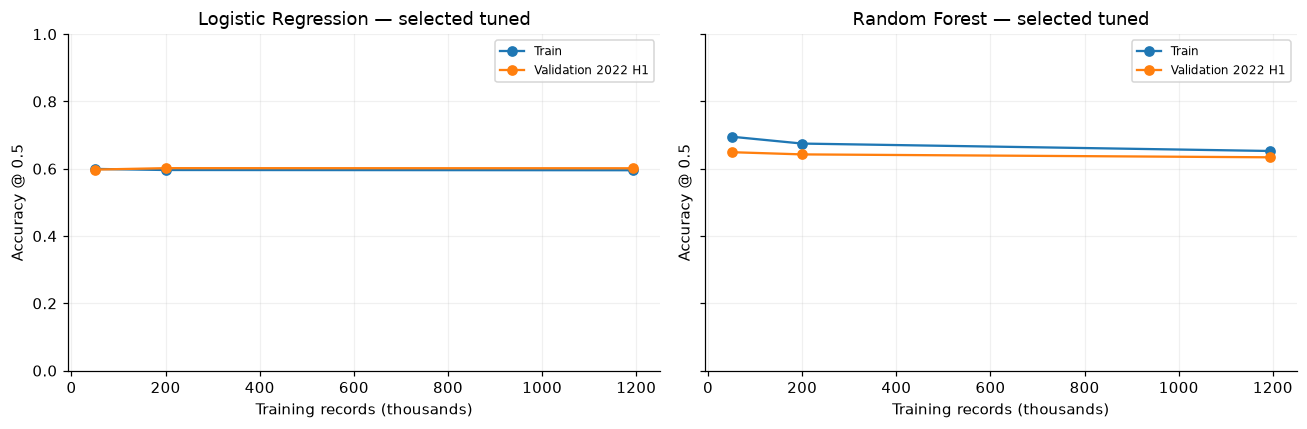

In [10]:
curve_order=np.random.default_rng(SEED).permutation(train_ids.to_numpy())
curve_sizes=sorted(set([min(n,len(train_ids)) for n in CURVE_SMALL_ROWS]+[len(train_ids)]))
curve_rows=[]
for name in NAMES:
    for variant in ['baseline','tuned']:
        params={} if variant=='baseline' else best_parameters[name]
        for size in curve_sizes:
            ids=pd.Index(np.sort(curve_order[:size]))
            if size==len(train_ids):
                matching=development_results.query('model==@name and variant==@variant')
                for split in ['train','validation_select']:
                    row=matching.loc[matching.split.eq(split)].iloc[0]
                    curve_rows.append({'model':name,'variant':variant,'train_rows':size,
                        'split':split,'F1':row.F1,'Accuracy':row.Accuracy})
            else:
                model=fit_pipeline(make_pipeline(name,params),ids,f'{name} {variant} learning curve n={size}')
                for split,eval_ids in [('train',ids),('validation_select',val_select_ids)]:
                    score,_=evaluate(model,eval_ids)
                    curve_rows.append({'model':name,'variant':variant,'train_rows':size,
                        'split':split,'F1':score['F1'],'Accuracy':score['Accuracy']})
                del model; gc.collect()
learning_results=pd.DataFrame(curve_rows)
display(learning_results)
fig,axes=plt.subplots(2,2,figsize=(12,8),sharex=True,sharey=True)
for i,name in enumerate(NAMES):
    for j,variant in enumerate(['baseline','tuned']):
        ax=axes[i,j]
        for split,label,marker in [('train','Train','o'),('validation_select','Validation 2022 H1','s')]:
            part=learning_results.query('model==@name and variant==@variant and split==@split').sort_values('train_rows')
            ax.plot(part.train_rows/1000,part.F1,marker=marker,label=label,
                    color=COLORS['train' if split=='train' else 'validation'])
        ax.set(title=f'{name} — {variant}',xlabel='Training records (thousands)',ylabel='Delayed-class F1 @ 0.5',ylim=(0,1))
        ax.legend(loc='best',fontsize=8)
fig.suptitle('Learning curves: training versus later validation',fontsize=14)
fig.tight_layout(); plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,name in zip(axes,NAMES):
    variant=chosen_variants[name]
    for split,label in [('train','Train'),('validation_select','Validation 2022 H1')]:
        part=learning_results.query('model==@name and variant==@variant and split==@split').sort_values('train_rows')
        ax.plot(part.train_rows/1000,part.Accuracy,marker='o',label=label)
    ax.set(title=f'{name} — selected {variant}',xlabel='Training records (thousands)',ylabel='Accuracy @ 0.5',ylim=(0,1))
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

### 11. วินิจฉัย overfit และผลของการแก้
เปรียบเทียบ baseline กับ tuned ที่ threshold เดียวกัน การลด gap โดย validation แย่ลงไม่ถือว่าสำเร็จ
gap มากกว่า 0.08 ใช้เป็นเพียงสัญญาณคัดกรองที่เปิดเผย ไม่ใช่ statistical test และยังอาจสะท้อน temporal drift

**อ่านร่วมกับ AP/ROC-AUC ในตารางข้อ 9:** baseline ที่แทบไม่ทาย positive อาจมี F1 ใกล้ศูนย์ทั้ง train/validation
จน F1 gap บดบังการจำข้อมูล จึงไม่ใช้ gap นี้อย่างเดียวตัดสิน ในรอบที่แนบ:

| RF configuration | Train AP | Validation AP | AP gap | Train ROC-AUC | Validation ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Baseline | 0.4736 | 0.3189 | 0.1547 | 0.7865 | 0.6368 |
| Tuned | 0.3072 | 0.3153 | -0.0081 | 0.6967 | 0.6349 |

ข้อจำกัดความลึก/ขนาดใบ/การสุ่ม/rare-category cap ลดช่องว่าง ranking ของ RF แต่ validation AP ลดลงเล็กน้อยด้วย
จึงไม่อ้างว่าการลด gap ทำให้ ranking แม่นขึ้น หรือแก้ overfit หมดแล้ว ผล F1/Recall ที่ดีขึ้นรวมผลน้ำหนักคลาสและ threshold
learning curves ค่อนข้างราบและยังมีความต่างข้ามปี จึงต้องแยก limited signal/underfitting ออกจาก overfit
ตารางนี้ตีความค่าที่รันแล้ว ไม่เปลี่ยนพารามิเตอร์จากผล test และหากเปลี่ยน configuration ให้คำนวณจากตารางข้อ 9 ของรอบใหม่


In [11]:
gap_rows=[]
for name in NAMES:
    for variant in ['baseline','tuned']:
        part=development_results.query('model==@name and variant==@variant').set_index('split')
        gap_rows.append({'model':name,'variant':variant,
            'train_F1':part.loc['train','F1'],'validation_F1':part.loc['validation_select','F1'],
            'F1_gap':part.loc['train','F1']-part.loc['validation_select','F1'],
            'train_Accuracy':part.loc['train','Accuracy'],
            'validation_Accuracy':part.loc['validation_select','Accuracy'],
            'Accuracy_gap':part.loc['train','Accuracy']-part.loc['validation_select','Accuracy']})
overfit_table=pd.DataFrame(gap_rows)
display(overfit_table)
for name in NAMES:
    part=overfit_table.loc[overfit_table.model.eq(name)].set_index('variant')
    delta=part.loc['tuned','validation_F1']-part.loc['baseline','validation_F1']
    gap_change=part.loc['tuned','F1_gap']-part.loc['baseline','F1_gap']
    display(Markdown(f'**{name}:** validation F1 เปลี่ยน {delta:+.4f}; train–validation F1 gap เปลี่ยน {gap_change:+.4f}. '
        + ('มีสัญญาณ gap สูง ต้องอ่านร่วมกับ learning curves และความต่างข้ามปี' if part.loc['baseline','F1_gap']>.08 else 'ไม่พบ gap สูงตามเกณฑ์คัดกรองนี้ แต่ยังไม่ใช่หลักฐานว่าไม่มี overfit')
        + f'. เลือก **{chosen_variants[name]}** จาก validation ไม่บังคับว่าการจูนต้องดีขึ้นเสมอ'))

,model,variant,train_F1,validation_F1,F1_gap,train_Accuracy,validation_Accuracy,Accuracy_gap
0,Logistic Regression,baseline,0.0004,0.0005,-0.0002,0.8384,0.7879,0.0506
1,Logistic Regression,tuned,0.3288,0.3831,-0.0543,0.5956,0.6014,-0.0058
2,Random Forest,baseline,0.0025,0.0002,0.0023,0.8386,0.7879,0.0508
3,Random Forest,tuned,0.3665,0.3767,-0.0101,0.6528,0.6340,0.0188


**Logistic Regression:** validation F1 เปลี่ยน +0.3826; train–validation F1 gap เปลี่ยน -0.0542. ไม่พบ gap สูงตามเกณฑ์คัดกรองนี้ แต่ยังไม่ใช่หลักฐานว่าไม่มี overfit. เลือก **tuned** จาก validation ไม่บังคับว่าการจูนต้องดีขึ้นเสมอ

**Random Forest:** validation F1 เปลี่ยน +0.3765; train–validation F1 gap เปลี่ยน -0.0125. ไม่พบ gap สูงตามเกณฑ์คัดกรองนี้ แต่ยังไม่ใช่หลักฐานว่าไม่มี overfit. เลือก **tuned** จาก validation ไม่บังคับว่าการจูนต้องดีขึ้นเสมอ

### 12. เลือก threshold ด้วย validation อีกครึ่งปี แล้วล็อกการตั้งค่า
ใช้ Jul–Dec 2022 ที่ไม่ได้ใช้เลือก configuration เลือก threshold ตาม F1; กริดกำหนดก่อนดู test
แสดง Precision/Recall/Accuracy ควบคู่ เมื่อเลือกเสร็จแล้วห้ามเปลี่ยนจากผล test

,model,variant,threshold,parameters
0,Logistic Regression,tuned,0.4950,"{'model__C': 0.03, 'model__class_weight': 'bal..."
1,Random Forest,tuned,0.4750,{'preprocess__cat__onehot__max_categories': 64...


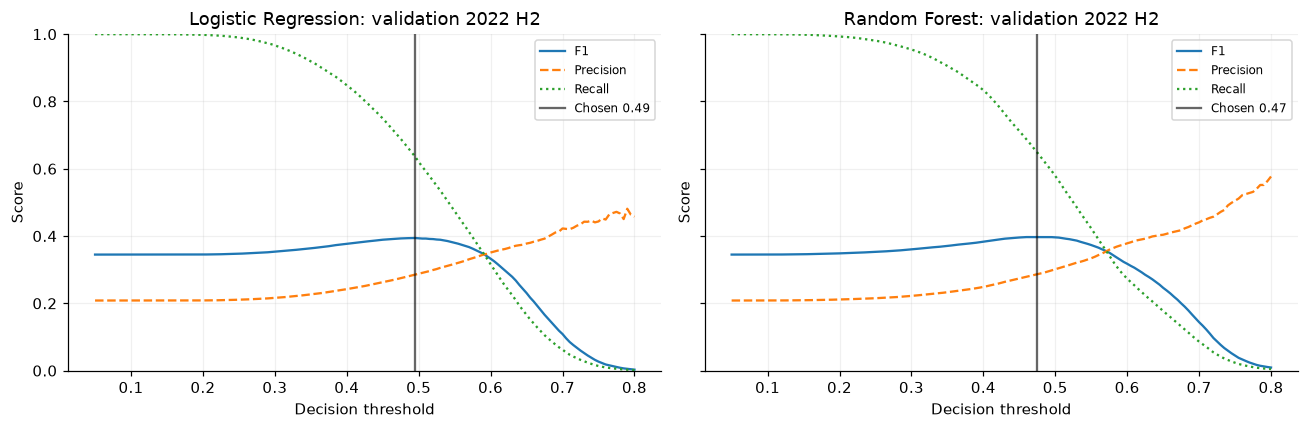

In [12]:
threshold_rows=[]
threshold_choices={}
for name in NAMES:
    variant=chosen_variants[name]
    _,prob=evaluate(models[(name,variant)],val_threshold_ids)
    for threshold in THRESHOLD_GRID:
        prediction=prob>=threshold
        threshold_rows.append({'model':name,'variant':variant,'threshold':float(threshold),
            'F1':f1_score(y.loc[val_threshold_ids],prediction,zero_division=0),
            'Precision':precision_score(y.loc[val_threshold_ids],prediction,zero_division=0),
            'Recall':recall_score(y.loc[val_threshold_ids],prediction,zero_division=0),
            'Accuracy':accuracy_score(y.loc[val_threshold_ids],prediction)})
    local=pd.DataFrame([r for r in threshold_rows if r['model']==name])
    winner=local.sort_values(['F1','Precision'],ascending=False,kind='stable').iloc[0]
    threshold_choices[name]=float(winner.threshold)
threshold_results=pd.DataFrame(threshold_rows)
locked_settings=pd.DataFrame([{'model':name,'variant':chosen_variants[name],
    'threshold':threshold_choices[name],
    'parameters':{} if chosen_variants[name]=='baseline' else best_parameters[name]} for name in NAMES])
display(locked_settings)
fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,name in zip(axes,NAMES):
    part=threshold_results.loc[threshold_results.model.eq(name)]
    ax.plot(part.threshold,part.F1,label='F1')
    ax.plot(part.threshold,part.Precision,label='Precision',linestyle='--')
    ax.plot(part.threshold,part.Recall,label='Recall',linestyle=':')
    ax.axvline(threshold_choices[name],color='black',alpha=.6,label=f'Chosen {threshold_choices[name]:.2f}')
    ax.set(title=f'{name}: validation 2022 H2',xlabel='Decision threshold',ylabel='Score',ylim=(0,1))
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
SETTINGS_LOCKED=True

### 13. เปิด test ปี 2023 ครั้งสุดท้าย: metrics ครบและ confusion matrix
ประเมินทั้ง baseline@0.5 กับ selected configuration+threshold ที่ล็อกไว้ก่อนหน้านี้
ผลก่อน–หลังใน test รวมผลของพารามิเตอร์และ threshold; ตาราง validation@0.5 ก่อนหน้าใช้แยกผลพารามิเตอร์
ตัวเลขทั้งหมดคำนวณจากไฟล์จริง ไม่มีการใช้คะแนน test ย้อนกลับไปเลือกโมเดล

,model,stage,variant,threshold,test_rows,Accuracy,Precision,Recall,F1,AP,ROC_AUC,Brier
0,Logistic Regression,Baseline @0.5,baseline,0.5000,304458,0.7704,0.6471,0.0002,0.0003,0.3376,0.6348,0.1735
1,Logistic Regression,Selected + threshold,tuned,0.4950,304458,0.5753,0.3015,0.6457,0.4111,0.3351,0.6347,0.2399
2,Random Forest,Baseline @0.5,baseline,0.5000,304458,0.7704,0.6000,0.0000,0.0001,0.3511,0.6475,0.1731
3,Random Forest,Selected + threshold,tuned,0.4750,304458,0.5790,0.3045,0.6493,0.4146,0.3504,0.6459,0.2293


Test prevalence: delayed=0.2296; eligible records=304,458


,reference,Accuracy,Precision,Recall,F1,AP,ROC_AUC,Brier
0,Constant training prevalence,0.7704,0.0000,0.0000,0.0000,0.2296,0.5000,0.1815


**Logistic Regression — classification report**

,precision,recall,f1-score,support
On time (<15 min),0.8400,0.5543,0.6679,"234,559.0000"
Delayed (>=15 min),0.3015,0.6457,0.4111,"69,899.0000"
macro avg,0.5708,0.6000,0.5395,"304,458.0000"
weighted avg,0.7164,0.5753,0.6089,"304,458.0000"


**Random Forest — classification report**

,precision,recall,f1-score,support
On time (<15 min),0.8423,0.5581,0.6714,"234,559.0000"
Delayed (>=15 min),0.3045,0.6493,0.4146,"69,899.0000"
macro avg,0.5734,0.6037,0.5430,"304,458.0000"
weighted avg,0.7188,0.5790,0.6124,"304,458.0000"


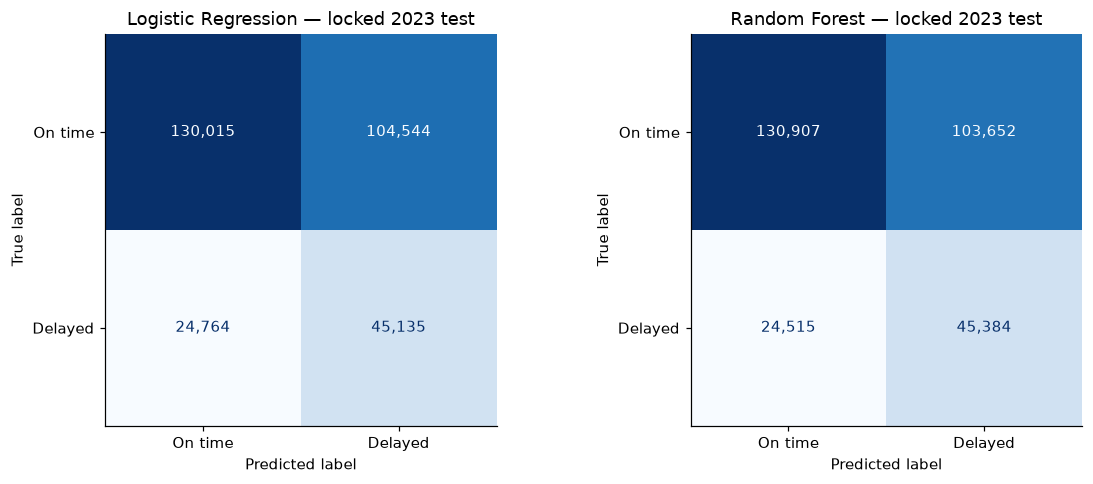

In [13]:
assert SETTINGS_LOCKED
assert y.loc[test_ids].nunique()==2
test_rows=[]
test_probabilities={}
test_reports={}
for name in NAMES:
    for stage,variant,threshold in [('Baseline @0.5','baseline',.5),
                                  ('Selected + threshold',chosen_variants[name],threshold_choices[name])]:
        score,prob=evaluate(models[(name,variant)],test_ids,threshold)
        test_rows.append({'model':name,'stage':stage,'variant':variant,'threshold':threshold,
                          'test_rows':len(test_ids),**score})
        if stage=='Selected + threshold':
            test_probabilities[name]=prob
            test_reports[name]=classification_report(y.loc[test_ids],prob>=threshold,
                labels=[0,1],target_names=['On time (<15 min)','Delayed (>=15 min)'],
                output_dict=True,zero_division=0)
test_results=pd.DataFrame(test_rows)
display(test_results)
print(f'Test prevalence: delayed={y.loc[test_ids].mean():.4f}; eligible records={len(test_ids):,}')
majority=np.full(len(test_ids),float(y.loc[train_ids].mean()))
display(pd.DataFrame([{'reference':'Constant training prevalence',
    **metrics_from_probability(y.loc[test_ids],majority,.5)}]))
for name in NAMES:
    display(Markdown('**'+name+' — classification report**'))
    display(pd.DataFrame({k:v for k,v in test_reports[name].items() if isinstance(v,dict)}).T)
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
for ax,name in zip(axes,NAMES):
    matrix=confusion_matrix(y.loc[test_ids],test_probabilities[name]>=threshold_choices[name],labels=[0,1])
    ConfusionMatrixDisplay(matrix,display_labels=['On time','Delayed']).plot(ax=ax,colorbar=False,cmap='Blues',values_format=',d')
    ax.set_title(f'{name} — locked 2023 test'); ax.grid(False)
fig.tight_layout(); plt.show()

### 14. PR/ROC และ calibration บน test ที่ล็อกไว้ — ใช้รายงานผลเท่านั้น

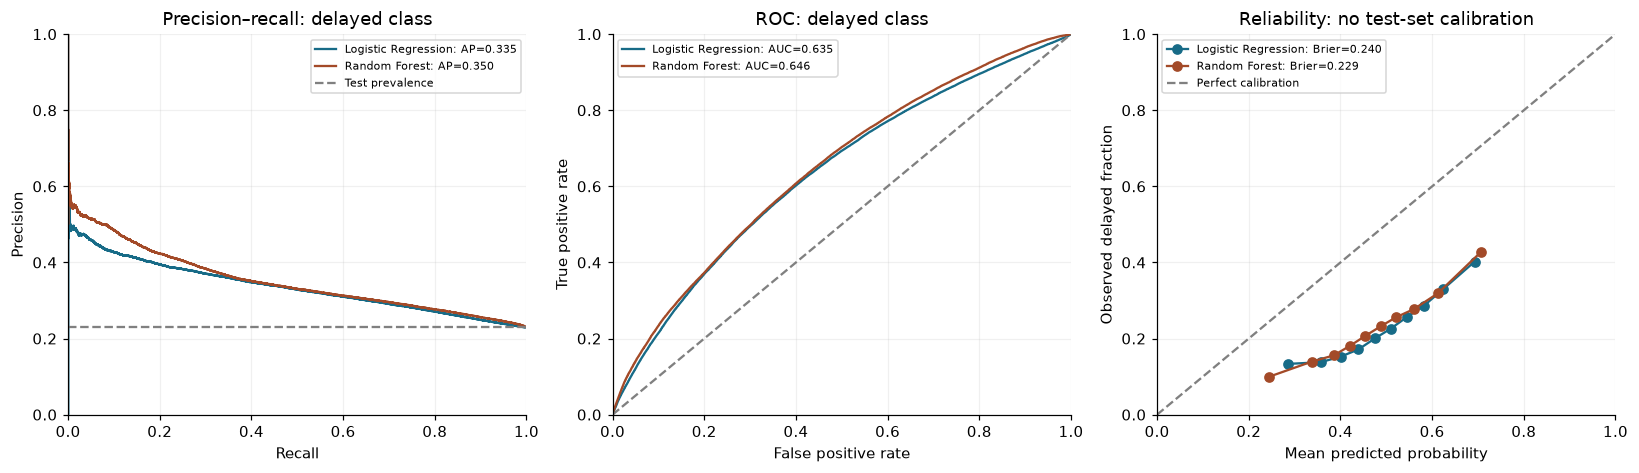

AP สรุป PR curve ตามนิยาม average precision ไม่ใช่ trapezoidal PR-AUC; Brier ต่ำดีกว่า ผล calibration ใช้ตรวจข้อจำกัดเท่านั้น ไม่ fit calibration จาก test

In [14]:
fig,axes=plt.subplots(1,3,figsize=(15,4.4))
for name in NAMES:
    prob=test_probabilities[name]
    precision,recall,_=precision_recall_curve(y.loc[test_ids],prob)
    fpr,tpr,_=roc_curve(y.loc[test_ids],prob)
    score=metrics_from_probability(y.loc[test_ids],prob,threshold_choices[name])
    axes[0].plot(recall,precision,color=COLORS[name],label=f"{name}: AP={score['AP']:.3f}")
    axes[1].plot(fpr,tpr,color=COLORS[name],label=f"{name}: AUC={score['ROC_AUC']:.3f}")
    fraction_positive,mean_probability=calibration_curve(y.loc[test_ids],prob,n_bins=10,strategy='quantile')
    axes[2].plot(mean_probability,fraction_positive,'o-',color=COLORS[name],
        label=f"{name}: Brier={score['Brier']:.3f}")
axes[0].axhline(y.loc[test_ids].mean(),color='gray',linestyle='--',label='Test prevalence')
axes[1].plot([0,1],[0,1],'--',color='gray')
axes[2].plot([0,1],[0,1],'--',color='gray',label='Perfect calibration')
axes[0].set(title='Precision–recall: delayed class',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1))
axes[1].set(title='ROC: delayed class',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1))
axes[2].set(title='Reliability: no test-set calibration',xlabel='Mean predicted probability',ylabel='Observed delayed fraction',xlim=(0,1),ylim=(0,1))
for ax in axes: ax.legend(fontsize=7,loc='best')
fig.tight_layout(); plt.show()
display(Markdown('AP สรุป PR curve ตามนิยาม average precision ไม่ใช่ trapezoidal PR-AUC; '
    'Brier ต่ำดีกว่า ผล calibration ใช้ตรวจข้อจำกัดเท่านั้น ไม่ fit calibration จาก test'))

### 15. ตรวจความคงทนรายเดือนใน test และเวลาฝึกที่วัดจริง

,model,month,rows,delayed_rate,Accuracy,Precision,Recall,F1
0,Logistic Regression,2023-01,36002,0.2177,0.6007,0.2720,0.4971,0.3516
1,Logistic Regression,2023-02,33912,0.1878,0.4918,0.2260,0.7033,0.3421
2,Logistic Regression,2023-03,39150,0.2406,0.6623,0.3348,0.4090,0.3682
3,Logistic Regression,2023-04,37584,0.2312,0.6681,0.3398,0.4619,0.3916
4,Logistic Regression,2023-05,39335,0.1799,0.6193,0.2639,0.6238,0.3709
5,Logistic Regression,2023-06,38241,0.2706,0.4794,0.3246,0.8551,0.4706
6,Logistic Regression,2023-07,39592,0.2840,0.5434,0.3635,0.8093,0.5016
7,Logistic Regression,2023-08,40642,0.2193,0.5315,0.2816,0.7327,0.4068
8,Random Forest,2023-01,36002,0.2177,0.5689,0.2631,0.5442,0.3547
9,Random Forest,2023-02,33912,0.1878,0.4672,0.2241,0.7458,0.3446


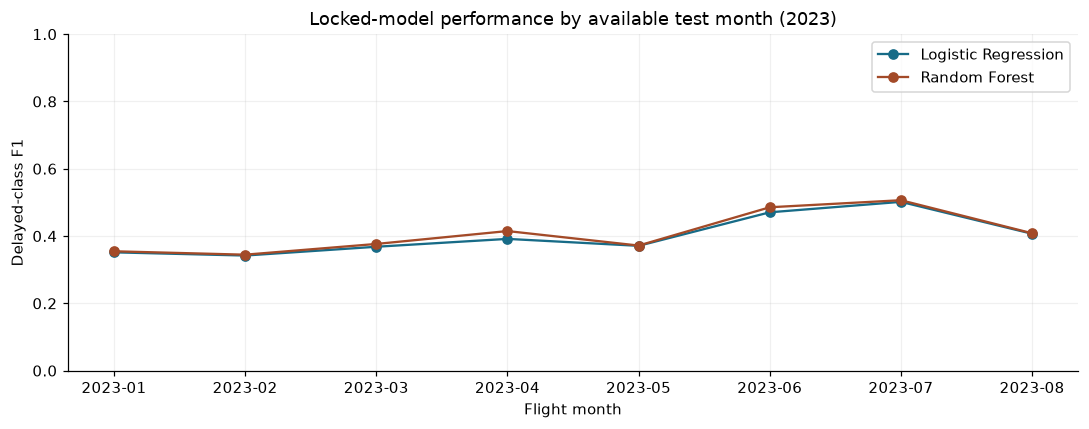

,fit,training_rows,fit_seconds
32,Logistic Regression baseline FULL TRAIN,1193757,14.0800
33,Logistic Regression tuned FULL TRAIN,1193757,15.1760
34,Random Forest baseline FULL TRAIN,1193757,342.1680
35,Random Forest tuned FULL TRAIN,1193757,450.4021


Observed wall time from notebook start: 17.8 minutes


In [15]:
monthly_rows=[]
test_month=dates.loc[test_ids].dt.to_period('M').astype(str).to_numpy()
actual=y.loc[test_ids].to_numpy()
for name in NAMES:
    prob=test_probabilities[name]
    for month in sorted(np.unique(test_month)):
        mask=test_month==month
        prediction=prob[mask]>=threshold_choices[name]
        monthly_rows.append({'model':name,'month':month,'rows':int(mask.sum()),
            'delayed_rate':float(actual[mask].mean()),'Accuracy':accuracy_score(actual[mask],prediction),
            'Precision':precision_score(actual[mask],prediction,zero_division=0),
            'Recall':recall_score(actual[mask],prediction,zero_division=0),
            'F1':f1_score(actual[mask],prediction,zero_division=0)})
monthly_test=pd.DataFrame(monthly_rows)
display(monthly_test)
fig,ax=plt.subplots(figsize=(10,4))
for name in NAMES:
    part=monthly_test.loc[monthly_test.model.eq(name)]
    ax.plot(part.month,part.F1,'o-',label=name,color=COLORS[name])
ax.set(title='Locked-model performance by available test month (2023)',xlabel='Flight month',ylabel='Delayed-class F1',ylim=(0,1))
ax.legend(); fig.tight_layout(); plt.show()
fit_times=pd.DataFrame(fit_records)
display(fit_times.loc[fit_times['fit'].str.contains('FULL TRAIN')])
print(f'Observed wall time from notebook start: {(time.perf_counter()-run_started)/60:.1f} minutes')

## Takeaways
### 16. สรุปจากผลที่รันจริง
การเลือก configuration/threshold เสร็จตั้งแต่ validation การเปรียบเทียบ test ด้านล่างเป็นรายงานเชิงพรรณนาเท่านั้น
ไม่เปลี่ยนพารามิเตอร์หลังเห็นผล และไม่เรียกว่าทำนายทุกเที่ยวบินได้ เพราะ cohort ไม่รวม cancellations/diversions

กราฟ calibration ที่แสดงมีคะแนนสูงเกินสัดส่วนล่าช้าที่เกิดจริงหลายช่วง จึงควรอ่านคะแนนเป็นผลทดลองของ classifier
ที่ใช้น้ำหนักคลาส ไม่อ้างว่าเป็นความน่าจะเป็นที่ calibrate แล้ว ไม่มีการแก้ calibration ด้วย test


In [16]:
final_summary=test_results.loc[test_results.stage.eq('Selected + threshold'),
    ['model','variant','threshold','test_rows','Accuracy','Precision','Recall','F1','AP','ROC_AUC','Brier']].reset_index(drop=True)
display(final_summary)
lines=[]
for _,row in final_summary.iterrows():
    lines.append(f"- **{row['model']}** ({row['variant']}, threshold={row['threshold']:.3f}): "
        f"Accuracy **{row['Accuracy']:.4f}**, Precision **{row['Precision']:.4f}**, "
        f"Recall **{row['Recall']:.4f}**, F1 **{row['F1']:.4f}**; AP={row['AP']:.4f}.")
display(Markdown('\n'.join(lines)))
display(Markdown(f'ใช้ข้อมูลดิบ **{raw_count:,}** แถว; หลังคลีนและกำหนด cohort **{len(data):,}** แถว; '
    f'train เต็ม **{len(train_ids):,}** แถว; test **{len(test_ids):,}** แถว. '
    f'ค้นพารามิเตอร์บน train สูงสุด **{len(cv_ids):,}** แถวด้วย 2 forward-year folds; '
    'ค่าที่เลือกดีที่สุดเฉพาะกรอบค้นหาที่แสดง ไม่ใช่ข้อรับรอง global optimum.'))
display(Markdown('**ข้อจำกัด:** schedule-only อธิบายอากาศ/การจราจรจริงไม่ครบ; sample สุ่มไม่ใช่ traffic ทั้งระบบ; '
    'ปี 2023 มีเฉพาะช่วงที่มีข้อมูล; temporal drift อาจปนใน train–validation gap; '
    'learning curves เป็น seed เดียว; rare-category grouping ลดรายละเอียด; '
    'ไม่มี prospective T−120 snapshot; precision/recall เปลี่ยนตาม threshold และ prevalence. '
    'โค้ดไม่มีการ export ข้อมูล โมเดล metrics หรือรูปออกเป็นไฟล์แยก'))
assert len(final_summary)==2
assert all(final_summary[['Accuracy','Precision','Recall','F1','AP','ROC_AUC']].ge(0).all())
assert all(final_summary[['Accuracy','Precision','Recall','F1','AP','ROC_AUC']].le(1).all())
assert sum(cleaning_audit.removed_n)+len(data)==raw_count
print('CHECKS PASSED: cohort reconciliation, chronological split, leakage exclusions, locked settings, metric ranges.')

,model,variant,threshold,test_rows,Accuracy,Precision,Recall,F1,AP,ROC_AUC,Brier
0,Logistic Regression,tuned,0.4950,304458,0.5753,0.3015,0.6457,0.4111,0.3351,0.6347,0.2399
1,Random Forest,tuned,0.4750,304458,0.5790,0.3045,0.6493,0.4146,0.3504,0.6459,0.2293


- **Logistic Regression** (tuned, threshold=0.495): Accuracy **0.5753**, Precision **0.3015**, Recall **0.6457**, F1 **0.4111**; AP=0.3351.
- **Random Forest** (tuned, threshold=0.475): Accuracy **0.5790**, Precision **0.3045**, Recall **0.6493**, F1 **0.4146**; AP=0.3504.

ใช้ข้อมูลดิบ **2,000,000** แถว; หลังคลีนและกำหนด cohort **1,942,769** แถว; train เต็ม **1,193,757** แถว; test **304,458** แถว. ค้นพารามิเตอร์บน train สูงสุด **180,000** แถวด้วย 2 forward-year folds; ค่าที่เลือกดีที่สุดเฉพาะกรอบค้นหาที่แสดง ไม่ใช่ข้อรับรอง global optimum.

**ข้อจำกัด:** schedule-only อธิบายอากาศ/การจราจรจริงไม่ครบ; sample สุ่มไม่ใช่ traffic ทั้งระบบ; ปี 2023 มีเฉพาะช่วงที่มีข้อมูล; temporal drift อาจปนใน train–validation gap; learning curves เป็น seed เดียว; rare-category grouping ลดรายละเอียด; ไม่มี prospective T−120 snapshot; precision/recall เปลี่ยนตาม threshold และ prevalence. โค้ดไม่มีการ export ข้อมูล โมเดล metrics หรือรูปออกเป็นไฟล์แยก

CHECKS PASSED: cohort reconciliation, chronological split, leakage exclusions, locked settings, metric ranges.


## แหล่งอ้างอิงและการทำซ้ำ
- [Kaggle dataset ที่ผู้ใช้ส่งมา](https://www.kaggle.com/datasets/patrickzel/flight-delay-and-cancellation-data-2019-2023-v2/data), dataset version 3; exact source และ SHA256 แสดงในเซลล์โหลด
- [BTS fields: ArrDel15, local time, planned/actual fields](https://www.transtats.bts.gov/Fields.asp?gnoyr_VQ=FGJ)
- [BTS Technical Directive 27: time reporting](https://www.bts.gov/topics/airlines-and-airports/%E2%80%A2-number-27-technical-directive-time-reporting-effective-jan-1-2018)
- [scikit-learn LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
- Breiman (2001), [Random Forests](https://doi.org/10.1023/A:1010933404324)
- Rebollo & Balakrishnan (2014), [Characterization and prediction of air traffic delays](https://doi.org/10.1016/j.trc.2014.04.007): บริบท/feature set ต่างจาก notebook นี้ ไม่ใช้คะแนนแทนผลจริง
- Saito & Rehmsmeier (2015), [PR versus ROC on imbalanced data](https://doi.org/10.1371/journal.pone.0118432)
- Roberts et al. (2017), [Structured-data cross-validation](https://doi.org/10.1111/ecog.02881)
- Kapoor & Narayanan (2023), [Data leakage and reproducibility](https://doi.org/10.1016/j.patter.2023.100804)

Notebook ใช้เฉพาะ input เดิมและแพ็กเกจที่ระบุ ไม่มีไฟล์ helper ที่ผู้ใช้ต้องโหลดจาก repo เพิ่ม กด Run All ใน kernel ใหม่ได้
ถ้าขยายงบจูน ให้เริ่มทดลองใหม่ทั้งกระบวนการและอย่าใช้ test ที่เคยเปิดดูแล้วเป็น validation อย่างเงียบ ๆ